# baseline 比較實驗：數據整理與論文用圖

資料來源：`src/strag_v3/eval/baseline/runs/` 的結果檔與評審檔（ptt_v2 共 50 題、5 個題型各 10 題）。

- 每張圖一個 cell，開頭的 `FIGSIZE`（英吋）直接改就能調整大小；共用的字體、字級、顏色、系統名稱都在下面第一個 cell。
- 圖和表存到這個 notebook 所在的 `src/strag_v3/eval/baseline/result/`，每張輸出一份 PNG。
- 逐題分數用專案自己的 `metrics.score_run` 算，並快取成 `baseline_scores.csv`；kernel 沒裝專案套件時會直接讀這份 CSV。

In [7]:
# ── 共用設定 ──────────────────────────────────────────────
import random, sqlite3, sys
from contextlib import closing
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "strag_v3").exists())
RUNS = ROOT / "src/strag_v3/eval/baseline/runs"
OUT = ROOT / "src/strag_v3/eval/baseline/result"
OUT.mkdir(parents=True, exist_ok=True)

FONT_SIZE = 9          # 全部圖的基準字級
DPI = 300              # PNG 解析度
FORMATS = ("png",)

# 系統的顯示順序與名稱（key 是 system 或 system_k<k>）
SYSTEMS = {
    "llm": "LLM（無檢索）",
    "dense_raw_k3": "Dense-Raw (k=3)",
    "dense_raw_k5": "Dense-Raw (k=5)",
    "dense_frag_k10": "Dense-Frag (k=10)",
    "dense_filter_k10": "Dense-Filter (k=10)",
    "strag": "ST-RAG（Ours）",
}
OURS = "strag"
TYPES = ["停留經驗", "移動經驗", "找地點", "找時間", "比較"]

# 顏色：本研究用強調色，baseline 用灰；P/R/F1 三個指標用色盲友善的三色
C_OURS, C_BASE = "#0072B2", "#A9A9A9"
C_METRIC = {"precision": "#0072B2", "recall": "#E69F00", "f1": "#009E73"}
INK, MUTED, GRID = "#1a1a1a", "#6b6b6b", "#e3e3e3"

plt.rcParams.update({
    "font.family": ["Helvetica Neue", "PingFang TC", "Heiti TC"],
    "font.size": FONT_SIZE, "axes.titlesize": FONT_SIZE + 1, "axes.labelsize": FONT_SIZE,
    "xtick.labelsize": FONT_SIZE, "ytick.labelsize": FONT_SIZE, "legend.fontsize": FONT_SIZE,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#a8a8a8", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK, "ytick.labelcolor": INK,
    "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.dpi": 130,
})


def save(fig, name):
    for ext in FORMATS:
        fig.savefig(OUT / f"{name}.{ext}", dpi=DPI)


def bar_colors(keys):
    return [C_OURS if k == OURS else C_BASE for k in keys]


def wrap(name):
    """直條圖的 x 軸標籤：括號前換行。"""
    return name.replace(" (", "\n(").replace("（", "\n（")

## 1. 載入逐題分數

In [8]:
SCORES_CSV = OUT / "baseline_scores.csv"


def compute_scores() -> pd.DataFrame:
    """每份評審檔 × 每題一列，分數用專案的 metrics.score_run 算。"""
    for p in (str(ROOT), str(ROOT / "src")):
        if p not in sys.path:
            sys.path.insert(0, p)
    from strag_v3.eval.baseline.fragments import load_fragments
    from strag_v3.eval.baseline.judge import Verdict
    from strag_v3.eval.baseline.metrics import score_run
    from strag_v3.eval.baseline.questions import load_questions
    from strag_v3.eval.baseline.results import load_judge, load_run

    questions = load_questions()
    with closing(sqlite3.connect(f"file:{ROOT / 'data/ptt.db'}?mode=ro", uri=True)) as conn:
        fragments = load_fragments(conn)
    rows = []
    for jp in sorted(RUNS.glob("*.judge.json")):
        data, run_path = load_judge(jp)
        config, outcomes = load_run(run_path)
        verdicts = [Verdict(**v) for v in data["questions"]]
        key = config["system"] + (f"_k{config['k']}" if config.get("k") is not None else "")
        for s in score_run(questions, outcomes, verdicts, fragments, config["retrieval"]):
            rows.append({"key": key, "retrieval": config["retrieval"], "run": run_path.name, **asdict(s)})
    return pd.DataFrame(rows)


try:
    scores = compute_scores()
    scores.to_csv(SCORES_CSV, index=False)
    print(f"重新計算，已寫入 {SCORES_CSV.relative_to(ROOT)}")
except ImportError as e:
    scores = pd.read_csv(SCORES_CSV)
    print(f"kernel 缺專案套件（{e.name}），改讀 {SCORES_CSV.relative_to(ROOT)}")

unknown = set(scores.key) - set(SYSTEMS)
assert not unknown, f"SYSTEMS 少了這些系統：{unknown}"
assert not scores.duplicated(["key", "id"]).any(), "同一個系統有多份評審檔，請在 RUNS 裡挑一份"
KEYS = [k for k in SYSTEMS if k in set(scores.key)]
scores.groupby("key").size().reindex(KEYS).rename("題數").to_frame().T

重新計算，已寫入 src/strag_v3/eval/baseline/result/baseline_scores.csv


key,llm,dense_raw_k3,dense_raw_k5,dense_frag_k10,dense_filter_k10,strag
題數,50,50,50,50,50,50


## 2. 彙總表

答案層兩項附 95% 信賴區間（逐題 bootstrap 10,000 次，固定種子，各系統重抽到同樣的題目）。時間違規率是所有題合起來算。

In [9]:
def bootstrap_ci(xs, seed=20261110, rounds=10_000):
    """跟 metrics.bootstrap_ci 同一個演算法與種子。"""
    xs = list(xs)
    rng, n = random.Random(seed), len(xs)
    means = sorted(sum(xs[rng.randrange(n)] for _ in range(n)) / n for _ in range(rounds))
    return means[int(0.025 * rounds)], means[int(0.975 * rounds) - 1]


def summarize(df: pd.DataFrame, ci=True) -> pd.Series:
    cov, uns = df.coverage.astype(float), df.unsupported.astype(float)
    out = {"n": len(df), "coverage": cov.mean(), "unsupported": uns.mean()}
    if ci:
        out["coverage_lo"], out["coverage_hi"] = bootstrap_ci(cov)
        out["unsupported_lo"], out["unsupported_hi"] = bootstrap_ci(uns)
    for m in ("article_recall", "precision", "recall", "f1"):
        out[m] = df[m].mean()                      # 不適用的系統整欄是 NaN
    retrieved = df.retrieved.sum()
    fragment = df.retrieval.iloc[0] == "fragment"
    out["violation_rate"] = (df.violations.sum() / retrieved if retrieved else 0.0) if fragment else np.nan
    for m in ("error", "place_unresolved", "empty"):
        out[m] = int(df[m].sum())
    for m in ("input_tokens", "llm_calls", "jev_calls"):
        out[m] = df[m].mean()
    return pd.Series(out)


summary = pd.DataFrame({k: summarize(scores[scores.key == k]) for k in KEYS}).T
summary.insert(0, "system", [SYSTEMS[k] for k in KEYS])
summary.to_csv(OUT / "baseline_summary.csv", index_label="key")

fmt_ci = lambda r, m: f"{r[m]:.3f} [{r[m + '_lo']:.3f}, {r[m + '_hi']:.3f}]"
num = lambda x, f="{:.3f}": "—" if pd.isna(x) else f.format(x)
main_table = pd.DataFrame({
    "系統": summary.system,
    "expect 覆蓋率 [95% CI]": summary.apply(fmt_ci, axis=1, m="coverage"),
    "無支持比例 [95% CI]": summary.apply(fmt_ci, axis=1, m="unsupported"),
    "文章 recall": summary.article_recall.map(num),
    "片段 P": summary.precision.map(num), "片段 R": summary.recall.map(num), "片段 F1": summary.f1.map(num),
    "時間違規率": summary.violation_rate.map(num),
    "地點解析不到": summary.place_unresolved, "取回為空": summary["empty"],
    "輸入 token／題": summary.input_tokens.map(lambda x: f"{x:.0f}"),
    "LLM 呼叫／題": summary.llm_calls.map(lambda x: f"{x:.1f}"),
    "JEV 呼叫／題": summary.jev_calls.map(lambda x: f"{x:.1f}"),
}).set_index("系統")
main_table.to_csv(OUT / "baseline_main_table.csv")
main_table

,expect 覆蓋率 [95% CI],無支持比例 [95% CI],文章 recall,片段 P,片段 R,片段 F1,時間違規率,地點解析不到,取回為空,輸入 token／題,LLM 呼叫／題,JEV 呼叫／題
系統,,,,,,,,,,,,
LLM（無檢索）,"0.371 [0.284, 0.461]","1.000 [1.000, 1.000]",—,—,—,—,—,0.0,0.0,1120,1.0,0.0
Dense-Raw (k=3),"0.165 [0.102, 0.234]","0.980 [0.940, 1.000]",0.338,—,—,—,—,0.0,0.0,3153,1.0,0.0
Dense-Raw (k=5),"0.238 [0.162, 0.319]","1.000 [1.000, 1.000]",0.429,—,—,—,—,0.0,0.0,4320,1.0,0.0
Dense-Frag (k=10),"0.583 [0.487, 0.676]","0.820 [0.720, 0.920]",0.632,0.157,0.528,0.233,0.498,0.0,0.0,3498,1.0,0.0
Dense-Filter (k=10),"0.738 [0.625, 0.842]","0.520 [0.380, 0.660]",0.746,0.478,0.735,0.549,0.000,8.0,2.0,5189,2.0,0.0
ST-RAG（Ours）,"0.988 [0.971, 1.000]","0.580 [0.440, 0.720]",1.000,0.757,1.000,0.837,0.000,0.0,0.0,3803,2.0,9.5


In [10]:
# 依題型（每個題型 10 題，只列平均）
by_type = pd.concat({
    (k, t): summarize(scores[(scores.key == k) & (scores.type == t)], ci=False)
    for k in KEYS for t in TYPES}, axis=1).T
by_type.index.names = ["key", "type"]
by_type.to_csv(OUT / "baseline_by_type.csv")

pivot = lambda m: by_type[m].astype(float).unstack("type").reindex(index=KEYS, columns=TYPES).rename(index=SYSTEMS)
pd.concat({"expect 覆蓋率": pivot("coverage"), "無支持比例": pivot("unsupported"), "片段 F1": pivot("f1")},
          axis=1).round(3).fillna("—")

/var/folders/y3/zm4n_k8n6mgc6ywc2k4vhmp40000gn/T/ipykernel_90514/3814113582.py:10: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  axis=1).round(3).fillna("—")


expect 覆蓋率                             無支持比例            \
type                      停留經驗   移動經驗    找地點    找時間     比較  停留經驗 移動經驗  找地點   
key                                                                          
LLM（無檢索）                 0.414  0.265  0.219  0.395  0.563   1.0  1.0  1.0   
Dense-Raw (k=3)          0.233  0.065  0.175  0.170  0.181   0.9  1.0  1.0   
Dense-Raw (k=5)          0.342  0.170  0.254  0.220  0.204   1.0  1.0  1.0   
Dense-Frag (k=10)        0.720  0.548  0.536  0.514  0.598   0.6  1.0  0.9   
Dense-Filter (k=10)      0.867  0.975  0.040  0.824  0.986   0.4  0.6  0.0   
ST-RAG（Ours）             0.967  1.000  1.000  0.973  1.000   0.4  0.5  0.4   

                               片段 F1                              
type                 找時間   比較   停留經驗   移動經驗    找地點    找時間     比較  
key                                                               
LLM（無檢索）             1.0  1.0      —      —      —      —      —  
Dense-Raw (k=3)      1.0  1.0      —      —      —      —      —  
Dense-Raw (k=5)      1.0  1.0      —      —      —      —      —  
Dense-Frag (k=10)    0.8  0.8  0.238  0.177  0.217  0.288  0.242  
Dense-Filter (k=10)  0.9  0.7   0.67  0.661   0.04  0.672    0.7  
ST-RAG（Ours）         0.9  0.7  0.815  0.898  0.914  0.688  0.871

## 圖 1　答案品質：expect 覆蓋率與無支持答案比例

誤差線是 95% 信賴區間。

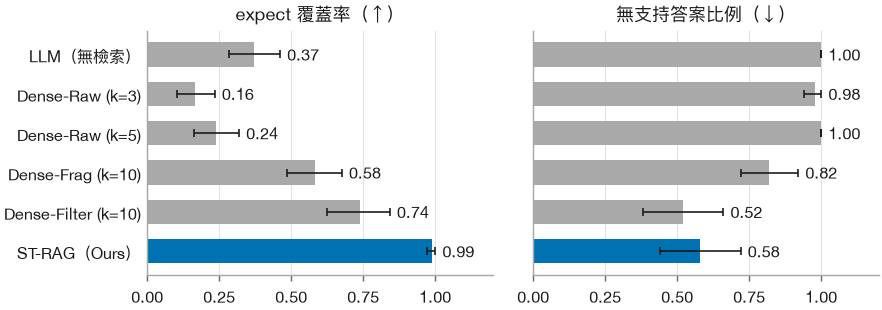

In [11]:
FIGSIZE = (7.0, 2.6)
BAR_H = 0.62

fig, axes = plt.subplots(1, 2, figsize=FIGSIZE, sharey=True)
y = np.arange(len(KEYS))[::-1]
for ax, (m, title) in zip(axes, [("coverage", "expect 覆蓋率（↑）"), ("unsupported", "無支持答案比例（↓）")]):
    v, lo, hi = (summary[c].astype(float).values for c in (m, m + "_lo", m + "_hi"))
    ax.barh(y, v, height=BAR_H, color=bar_colors(KEYS))
    ax.errorbar(v, y, xerr=[v - lo, hi - v], fmt="none", ecolor=INK, elinewidth=0.9, capsize=2.2, capthick=0.9)
    for yi, vi, hi_i in zip(y, v, hi):
        ax.text(hi_i + 0.025, yi, f"{vi:.2f}", va="center", ha="left")
    ax.set(xlim=(0, 1.2), title=title)
    ax.set_xticks(np.arange(0, 1.01, 0.25))
    ax.grid(axis="x")
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(y, [SYSTEMS[k] for k in KEYS])
fig.tight_layout(w_pad=1.5)
save(fig, "baseline_answer")

## 圖 2　文章級 recall

`LLM` 沒有檢索，不列。

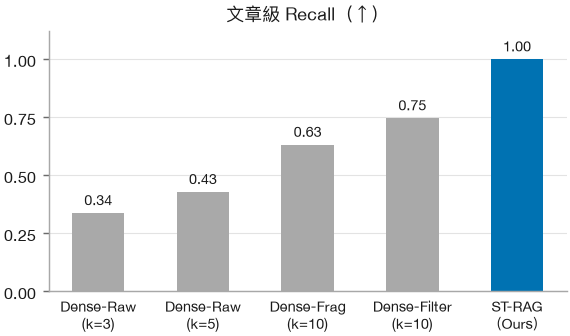

In [12]:
FIGSIZE = (4.6, 2.8)
BAR_W = 0.5

keys = [k for k in KEYS if pd.notna(summary.article_recall[k])]
v = summary.article_recall[keys].astype(float).values
x = np.arange(len(keys))
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.bar(x, v, width=BAR_W, color=bar_colors(keys))
for xi, vi in zip(x, v):
    ax.text(xi, vi + 0.02, f"{vi:.2f}", ha="center", va="bottom", fontsize=FONT_SIZE - 1)
ax.set(ylim=(0, 1.12), title="文章級 Recall（↑）")
ax.set_xticks(x, [wrap(SYSTEMS[k]) for k in keys], fontsize=FONT_SIZE - 1)
ax.set_yticks(np.arange(0, 1.01, 0.25))
ax.grid(axis="y")
ax.tick_params(axis="x", length=0)
fig.tight_layout()
save(fig, "baseline_article_recall")

## 圖 3　片段級檢索品質與時間違規率

只有取回片段的三個系統適用。

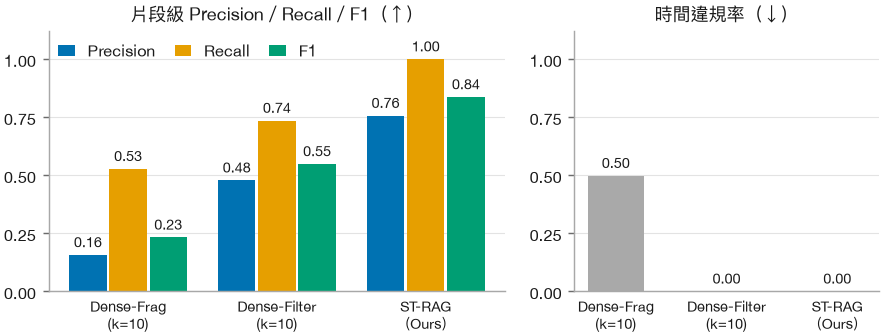

In [13]:
FIGSIZE = (7.0, 2.8)
WIDTH_RATIOS = (1.5, 1)   # 左右兩格的寬度比
BAR_W = 0.25

keys = [k for k in KEYS if pd.notna(summary.f1[k])]
x = np.arange(len(keys))
fig, (ax, ax2) = plt.subplots(1, 2, figsize=FIGSIZE, gridspec_kw={"width_ratios": WIDTH_RATIOS})

for i, (m, name) in enumerate([("precision", "Precision"), ("recall", "Recall"), ("f1", "F1")]):
    v = summary[m][keys].astype(float).values
    xs = x + (i - 1) * (BAR_W + 0.02)
    ax.bar(xs, v, width=BAR_W, color=C_METRIC[m], label=name)
    for xi, vi in zip(xs, v):
        ax.text(xi, vi + 0.02, f"{vi:.2f}", ha="center", va="bottom", fontsize=FONT_SIZE - 1)
ax.set(ylim=(0, 1.12), title="片段級 Precision／Recall／F1（↑）")
ax.legend(ncols=3, frameon=False, loc="upper left", handlelength=1, columnspacing=1.2, borderaxespad=0.2)

v = summary.violation_rate[keys].astype(float).values
ax2.bar(x, v, width=0.5, color=bar_colors(keys))
for xi, vi in zip(x, v):
    ax2.text(xi, vi + 0.02, f"{vi:.2f}", ha="center", va="bottom", fontsize=FONT_SIZE - 1)
ax2.set(ylim=(0, 1.12), title="時間違規率（↓）")

for a in (ax, ax2):
    a.set_xticks(x, [wrap(SYSTEMS[k]) for k in keys], fontsize=FONT_SIZE - 1)
    a.set_yticks(np.arange(0, 1.01, 0.25))
    a.grid(axis="y")
    a.tick_params(axis="x", length=0)
fig.tight_layout(w_pad=1.5)
save(fig, "baseline_retrieval")

## 圖 4　依題型的熱圖

`PANELS` 可以換指標（`coverage`、`unsupported`、`article_recall`、`precision`、`recall`、`f1`、`violation_rate`）；整列不適用的系統會自動略過。

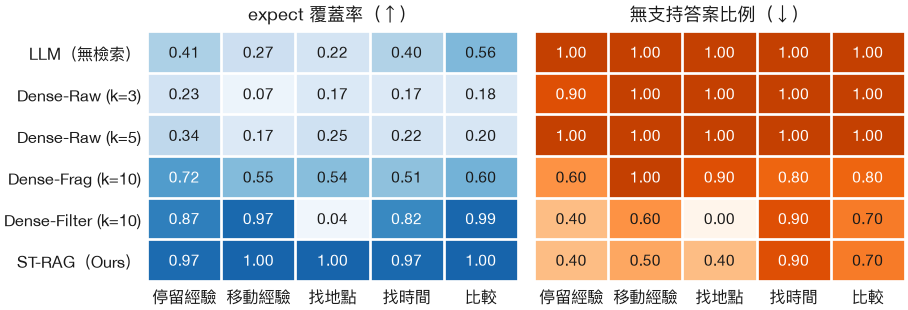

In [14]:
FIGSIZE = (7.2, 2.6)
PANELS = [("coverage", "expect 覆蓋率（↑）", "Blues"), ("unsupported", "無支持答案比例（↓）", "Oranges")]

fig, axes = plt.subplots(1, len(PANELS), figsize=FIGSIZE, squeeze=False)
shown = None
for ax, (m, title, cmap) in zip(axes[0], PANELS):
    tbl = by_type[m].astype(float).unstack("type").reindex(index=KEYS, columns=TYPES).dropna(how="all")
    ax.imshow(tbl.values, cmap=cmap, vmin=0, vmax=1.25, aspect="auto")   # vmax > 1：最深的顏色不要太黑
    for (i, j), val in np.ndenumerate(tbl.values):
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="white" if val > 0.7 else INK,
                fontsize=FONT_SIZE - 0.5)
    ax.set_xticks(range(len(TYPES)), TYPES)
    same = shown == list(tbl.index)
    ax.set_yticks(range(len(tbl)), [] if same else [SYSTEMS[k] for k in tbl.index])
    shown = list(tbl.index)
    ax.set_title(title)
    ax.tick_params(length=0)
    ax.set_xticks(np.arange(-0.5, len(TYPES)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(tbl)), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", length=0)
    for s in ax.spines.values():
        s.set_visible(False)
fig.tight_layout(w_pad=1.0)
save(fig, "baseline_by_type")

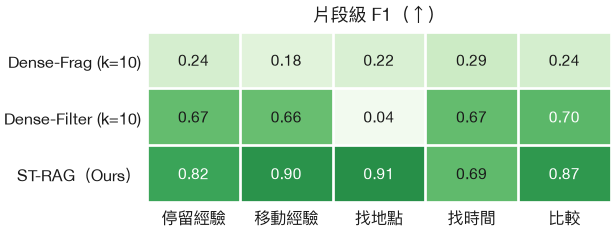

In [15]:
# 同一張熱圖，換成片段級 F1（只有三個片段系統）
FIGSIZE = (4.6, 1.7)

tbl = by_type["f1"].astype(float).unstack("type").reindex(index=KEYS, columns=TYPES).dropna(how="all")
fig, ax = plt.subplots(figsize=FIGSIZE)
ax.imshow(tbl.values, cmap="Greens", vmin=0, vmax=1.25, aspect="auto")
for (i, j), val in np.ndenumerate(tbl.values):
    ax.text(j, i, f"{val:.2f}", ha="center", va="center", color="white" if val > 0.7 else INK,
            fontsize=FONT_SIZE - 0.5)
ax.set_xticks(range(len(TYPES)), TYPES)
ax.set_yticks(range(len(tbl)), [SYSTEMS[k] for k in tbl.index])
ax.set_title("片段級 F1（↑）")
ax.set_xticks(np.arange(-0.5, len(TYPES)), minor=True)
ax.set_yticks(np.arange(-0.5, len(tbl)), minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="both", length=0)
for s in ax.spines.values():
    s.set_visible(False)
save(fig, "baseline_by_type_f1")

## 圖 5　成本與答案品質

橫軸是每題交給生成器的輸入 token，縱軸是 expect 覆蓋率。`OFFSETS` 調整各標籤的位置（單位：點）。

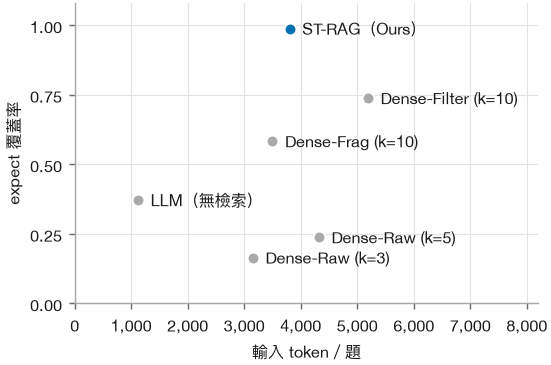

In [16]:
FIGSIZE = (4.6, 3.0)
OFFSETS = {}          # 例如 {"dense_frag_k10": (6, -10)}；沒寫的用 DEFAULT_OFFSET
DEFAULT_OFFSET = (7, 0)

fig, ax = plt.subplots(figsize=FIGSIZE)
for k in KEYS:
    xk, yk = float(summary.input_tokens[k]), float(summary.coverage[k])
    ax.scatter(xk, yk, s=42, color=C_OURS if k == OURS else C_BASE, edgecolor="white", linewidth=1, zorder=3)
    dx, dy = OFFSETS.get(k, DEFAULT_OFFSET)
    ax.annotate(SYSTEMS[k], (xk, yk), xytext=(dx, dy), textcoords="offset points",
                va="center", ha="left" if dx >= 0 else "right")
ax.set(xlim=(0, 8200), ylim=(0, 1.08), xlabel="輸入 token／題", ylabel="expect 覆蓋率")
ax.set_yticks(np.arange(0, 1.01, 0.25))
ax.xaxis.set_major_formatter(lambda v, _: f"{v:,.0f}")
ax.grid(True)
save(fig, "baseline_cost")

## 表　成本與失敗題數

In [17]:
cost = summary[["system", "input_tokens", "llm_calls", "jev_calls", "error", "place_unresolved", "empty"]].copy()
cost.columns = ["系統", "輸入 token／題", "LLM 呼叫／題", "JEV 呼叫／題", "出錯", "地點解析不到", "取回為空"]
cost["輸入 token／題"] = cost["輸入 token／題"].astype(float).round(0).astype(int)
cost[["LLM 呼叫／題", "JEV 呼叫／題"]] = cost[["LLM 呼叫／題", "JEV 呼叫／題"]].astype(float).round(1)
cost[["出錯", "地點解析不到", "取回為空"]] = cost[["出錯", "地點解析不到", "取回為空"]].astype(int)
cost.set_index("系統")

,輸入 token／題,LLM 呼叫／題,JEV 呼叫／題,出錯,地點解析不到,取回為空
系統,,,,,,
LLM（無檢索）,1120,1.0,0.0,0,0,0
Dense-Raw (k=3),3153,1.0,0.0,0,0,0
Dense-Raw (k=5),4320,1.0,0.0,0,0,0
Dense-Frag (k=10),3498,1.0,0.0,0,0,0
Dense-Filter (k=10),5189,2.0,0.0,0,8,2
ST-RAG（Ours）,3803,2.0,9.5,0,0,0
